# DS605 Lab Assignment 8
## Decision Trees and Support Vector Machines

**Name:** HiteshSinh ManharSinh Rathod  
**Roll No.:** 202618040  
**Dataset:** UCI Banknote Authentication

**Contents:**
- Part A: Decision Tree from scratch
- Part B: Linear SVM from scratch
- Part C: Kernel SVM on a nonlinear dataset
- Part D: Final comparison using all four features

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

np.random.seed(42)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Banknote dataset

The file has no header, so column names are supplied manually.
The code checks the `data` folder inside the current lab directory.

In [2]:
column_names = ["variance", "skewness", "curtosis", "entropy", "class"]

# Looking in the 'data' folder relative to this notebook
file_path = Path("data") / "data_banknote_authentication.txt"

if not file_path.exists():
    raise FileNotFoundError(
        f"Could not find the dataset at {file_path.resolve()}. "
        "Make sure the text file is inside the 'data' folder."
    )

df = pd.read_csv(file_path, header=None, names=column_names)

print("File loaded from:", file_path.resolve())
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset info:")
df.info()

print("\nClass counts:")
print(df["class"].value_counts().sort_index())

print("\nMissing values per column:")
print(df.isnull().sum())

File loaded from: /Users/hitesh/Desktop/202618040/ML/LAB08/data/data_banknote_authentication.txt
Dataset shape: (1372, 5)

First five rows:


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Class counts:
class
0    762
1    610
Name: count, dtype: int64

Missing values per column:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


## 3. Quick look at the data

Summary statistics for the four features, class balance, and the feature distributions.

,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495


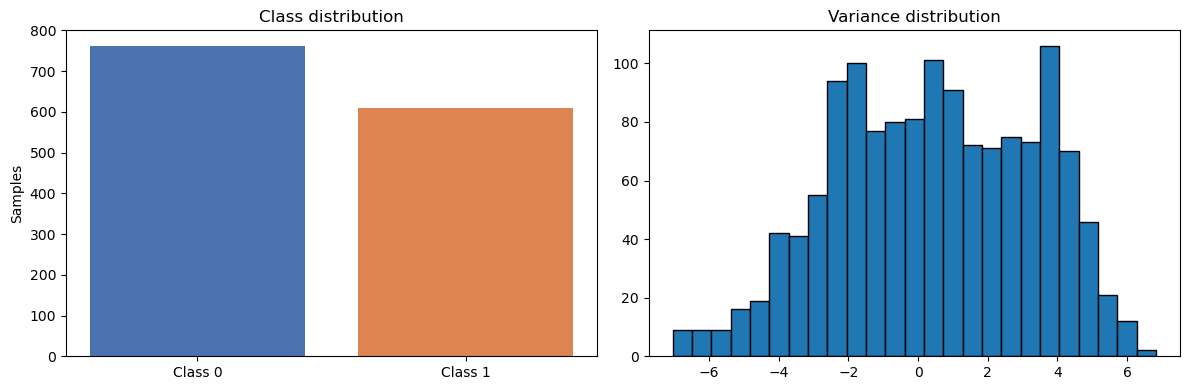

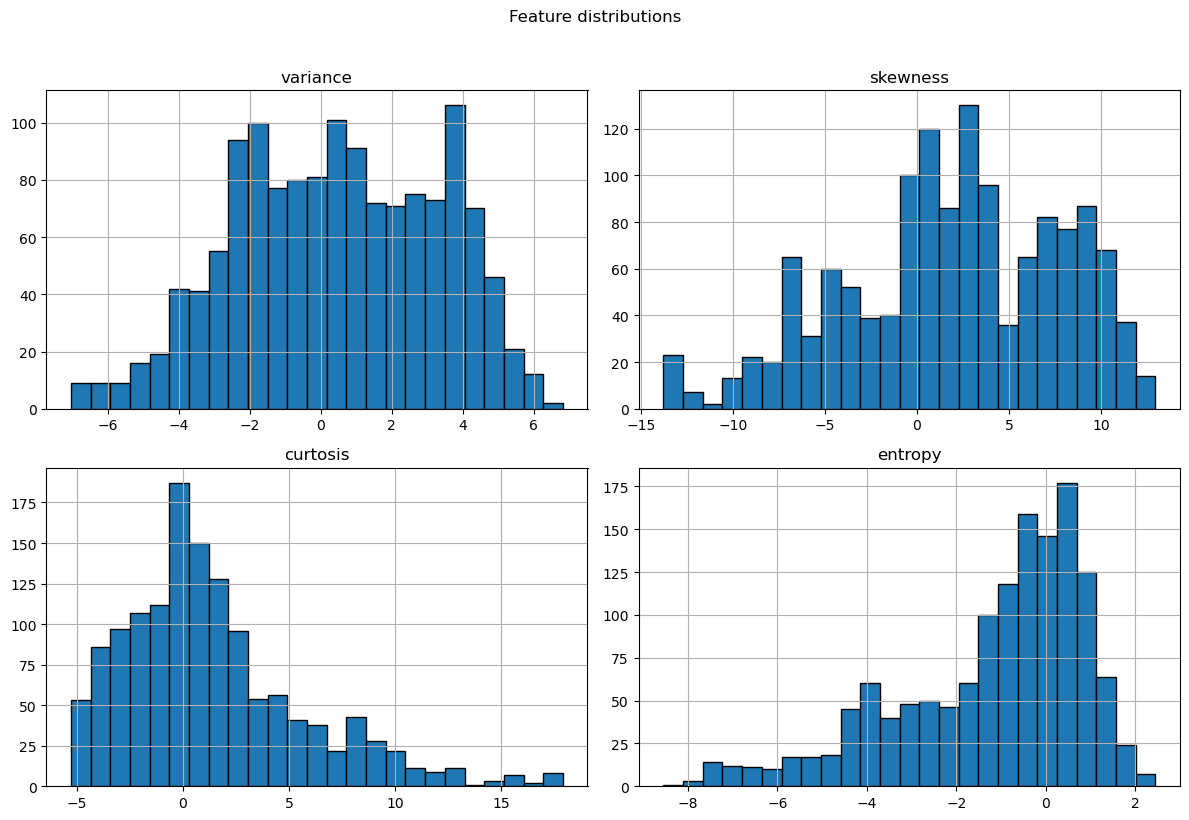

In [3]:
display(df.iloc[:, :4].describe().T)

counts = df["class"].value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(["Class 0", "Class 1"], counts.values, color=["#4C72B0", "#DD8452"])
ax[0].set_ylabel("Samples")
ax[0].set_title("Class distribution")

ax[1].hist(df["variance"], bins=25, edgecolor="black")
ax[1].set_title("Variance distribution")
plt.tight_layout()
plt.show()

df.iloc[:, :4].hist(figsize=(12, 8), bins=25, edgecolor="black")
plt.suptitle("Feature distributions", y=1.02)
plt.tight_layout()
plt.show()

## 4. Train/test split

80/20 split with stratification. Two features (`variance`, `skewness`) are kept aside for the 2D boundary plots; all four are used for the final comparison.

In [4]:
feature_cols = ["variance", "skewness", "curtosis", "entropy"]

X_all = df[feature_cols].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

# 80/20 split, stratified to keep class balance
X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all, y, test_size=0.20, random_state=42, stratify=y
)

# Extract just the first two features for 2D plots
feature_names_2d = ["variance", "skewness"]
idx_2d = [0, 1]
X_train_2d = X_train_all[:, idx_2d]
X_test_2d = X_test_all[:, idx_2d]

print("Full train shape:", X_train_all.shape, " Full test shape:", X_test_all.shape)
print("2D   train shape:", X_train_2d.shape,  " 2D   test shape:", X_test_2d.shape)

print("\nTrain class counts:", np.bincount(y_train))
print("Test  class counts:", np.bincount(y_test))

Full train shape: (1097, 4)  Full test shape: (275, 4)
2D   train shape: (1097, 2)  2D   test shape: (275, 2)

Train class counts: [609 488]
Test  class counts: [153 122]


## Part A: Decision Tree from Scratch

### 5. Impurity functions

Gini impurity: $1 - \sum p_i^2$
Entropy: $-\sum p_i \log_2(p_i)$

Both metrics are 0 when a node contains only one class (pure node).

In [5]:
def gini_impurity(y_node):
    if len(y_node) == 0:
        return 0.0
    _, counts = np.unique(y_node, return_counts=True)
    p = counts / len(y_node)
    return 1.0 - np.sum(p ** 2)

def entropy_impurity(y_node):
    if len(y_node) == 0:
        return 0.0
    _, counts = np.unique(y_node, return_counts=True)
    p = counts / len(y_node)
    return -np.sum(p * np.log2(p))

def weighted_child_impurity(y_left, y_right, criterion="gini"):
    n = len(y_left) + len(y_right)
    if n == 0:
        return 0.0

    # Select the correct function
    f = gini_impurity if criterion == "gini" else entropy_impurity

    # Calculate weighted average
    return (len(y_left) / n) * f(y_left) + (len(y_right) / n) * f(y_right)

# Quick sanity check
lbl = np.array([0, 0, 1, 1])
print("Gini (balanced):", gini_impurity(lbl))
print("Entropy (balanced):", entropy_impurity(lbl))
print("Gini (pure node):", gini_impurity(np.array([1, 1, 1])))

Gini (balanced): 0.5
Entropy (balanced): 1.0
Gini (pure node): 0.0


### 6. Best split search

For each feature, try the midpoints between consecutive sorted unique values as candidate thresholds. Score each split by weighted child impurity and keep the best one.

In [6]:
def find_best_split(X_node, y_node, criterion="gini"):
    n, d = X_node.shape
    if n < 2:
        return None, None, None

    best_feature, best_threshold, best_impurity = None, None, np.inf

    for f in range(d):
        values = np.unique(X_node[:, f])
        if len(values) < 2:
            continue

        # Midpoints between consecutive unique values
        thresholds = (values[:-1] + values[1:]) / 2.0

        for t in thresholds:
            left_mask = X_node[:, f] <= t
            y_left = y_node[left_mask]
            y_right = y_node[~left_mask]

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            imp = weighted_child_impurity(y_left, y_right, criterion)

            if imp < best_impurity:
                best_impurity = imp
                best_feature = f
                best_threshold = t

    return best_feature, best_threshold, best_impurity

# Test on a small dataset
X_demo = np.array([[1.0], [2.0], [3.0], [4.0]])
y_demo = np.array([0, 0, 1, 1])

f, t, imp = find_best_split(X_demo, y_demo, "gini")
print("Best feature:", f)
print("Best threshold:", t)
print("Child impurity:", imp)
print("Info gain:", gini_impurity(y_demo) - imp)

Best feature: 0
Best threshold: 2.5
Child impurity: 0.0
Info gain: 0.5


### 7. The tree class

Nodes are dictionaries holding the prediction, sample count, impurity, the chosen feature/threshold, and the left/right subtrees. 
Stopping rules: pure node, max depth reached, or too few samples to split.

In [7]:
class ManualDecisionTree:
    def __init__(self, criterion="gini", max_depth=5,
                 min_samples_split=2, min_samples_leaf=1):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root = None

    def _majority(self, y_node):
        classes, counts = np.unique(y_node, return_counts=True)
        return classes[np.argmax(counts)]

    def _impurity(self, y_node):
        return (gini_impurity(y_node) if self.criterion == "gini"
                else entropy_impurity(y_node))

    def _build(self, X, y, depth):
        node = {
            "prediction": self._majority(y),
            "samples": len(y),
            "impurity": self._impurity(y),
            "feature": None,
            "threshold": None,
            "left": None,
            "right": None,
        }

        # Stopping conditions
        if (node["impurity"] == 0
                or depth >= self.max_depth
                or len(y) < self.min_samples_split):
            return node

        f, t, imp = find_best_split(X, y, self.criterion)
        if f is None:
            return node

        left_mask = X[:, f] <= t

        # Enforce min_samples_leaf
        if (left_mask.sum() < self.min_samples_leaf
                or (~left_mask).sum() < self.min_samples_leaf):
            return node

        node["feature"] = f
        node["threshold"] = t
        node["gain"] = node["impurity"] - imp

        # Recursively build children
        node["left"] = self._build(X[left_mask], y[left_mask], depth + 1)
        node["right"] = self._build(X[~left_mask], y[~left_mask], depth + 1)

        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.root = self._build(X, y, 0)
        return self

    def _predict_one(self, x, node):
        if node["feature"] is None:
            return node["prediction"]
        if x[node["feature"]] <= node["threshold"]:
            return self._predict_one(x, node["left"])
        return self._predict_one(x, node["right"])

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(1, -1)
        return np.array([self._predict_one(x, self.root) for x in X])

    def print_tree(self, node=None, depth=0, feature_names=None):
        if node is None:
            node = self.root
        indent = "  " * depth

        if node["feature"] is None:
            print(f"{indent}-> predict={node['prediction']} (n={node['samples']})")
            return

        fname = feature_names[node["feature"]] if feature_names else node["feature"]
        print(f"{indent}if {fname} <= {node['threshold']:.4f} "
              f"(n={node['samples']}, gain={node.get('gain', 0):.4f})")
        self.print_tree(node["left"], depth + 1, feature_names)
        print(f"{indent}else:")
        self.print_tree(node["right"], depth + 1, feature_names)

### 8. Train and evaluate the manual tree (2 features)

In [8]:
# Initialize and train the manual tree
manual_tree = ManualDecisionTree(criterion="gini", max_depth=5)

t0 = time.perf_counter()
manual_tree.fit(X_train_2d, y_train)
train_time_tree = time.perf_counter() - t0

# Predict and time it
t0 = time.perf_counter()
y_pred_manual_tree = manual_tree.predict(X_test_2d)
predict_time_tree = time.perf_counter() - t0

print("Manual tree (2 features)")
print("Accuracy :", round(accuracy_score(y_test, y_pred_manual_tree), 4))
print("Precision:", round(precision_score(y_test, y_pred_manual_tree), 4))
print("Recall   :", round(recall_score(y_test, y_pred_manual_tree), 4))
print("F1       :", round(f1_score(y_test, y_pred_manual_tree), 4))
print("Train time (s):", round(train_time_tree, 4))
print("Predict time (s):", round(predict_time_tree, 5))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_manual_tree))

Manual tree (2 features)
Accuracy : 0.9309
Precision: 0.8815
Recall   : 0.9754
F1       : 0.9261
Train time (s): 0.1384
Predict time (s): 0.00012

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.90      0.94       153
           1       0.88      0.98      0.93       122

    accuracy                           0.93       275
   macro avg       0.93      0.94      0.93       275
weighted avg       0.94      0.93      0.93       275



### 9. Visualise the learned tree

Draw a compact tree diagram up to depth 3 so it stays readable.

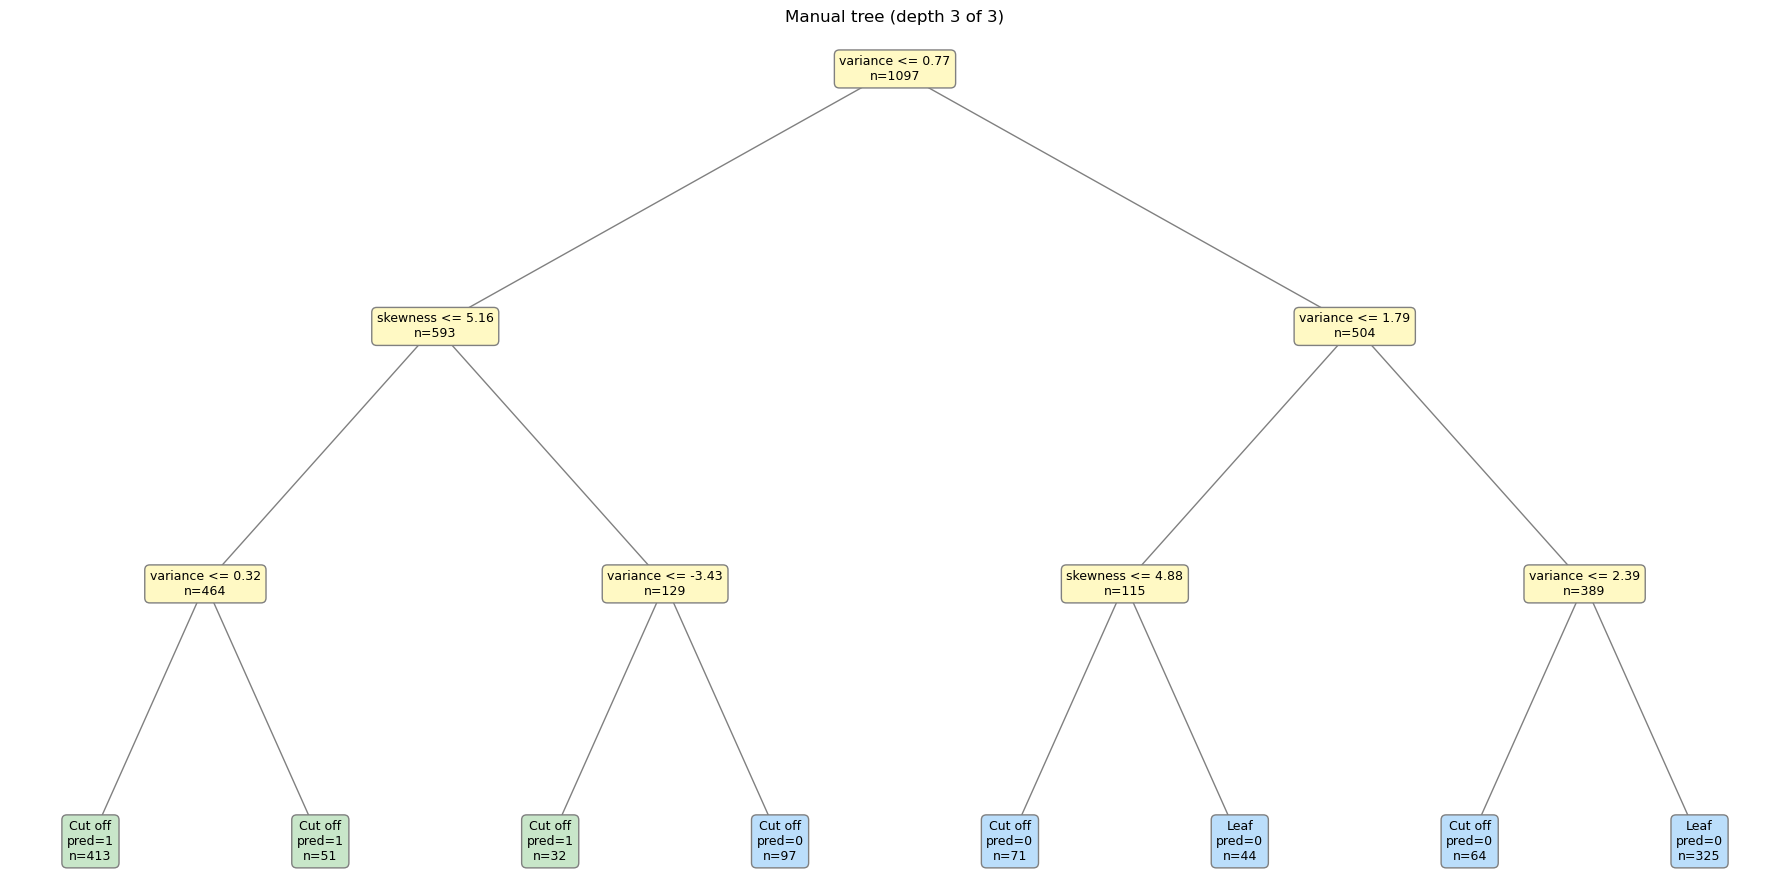

In [9]:
def draw_tree(node, feature_names, max_depth=3):
    fig, ax = plt.subplots(figsize=(18, 9))

    def leaves(n, d):
        if n["feature"] is None or d >= max_depth:
            return 1
        return leaves(n["left"], d + 1) + leaves(n["right"], d + 1)

    def draw(n, d, xl, xr, px=None, py=None):
        x = (xl + xr) / 2
        y = -d
        if px is not None:
            ax.plot([px, x], [py, y], color="gray", linewidth=1)

        if n["feature"] is None or d >= max_depth:
            text = (f"Leaf\npred={n['prediction']}\nn={n['samples']}"
                    if n["feature"] is None else
                    f"Cut off\npred={n['prediction']}\nn={n['samples']}")
            color = "#c8e6c9" if n["prediction"] == 1 else "#bbdefb"
        else:
            text = (f"{feature_names[n['feature']]} <= {n['threshold']:.2f}\n"
                    f"n={n['samples']}")
            color = "#fff9c4"

        ax.text(x, y, text, ha="center", va="center", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.4",
                          facecolor=color, edgecolor="gray"))

        if n["feature"] is not None and d < max_depth:
            l = leaves(n["left"], d + 1)
            r = leaves(n["right"], d + 1)
            split = xl + (xr - xl) * l / (l + r)
            draw(n["left"], d + 1, xl, split, x, y)
            draw(n["right"], d + 1, split, xr, x, y)

    draw(node, 0, 0, leaves(node, 0))
    ax.set_title(f"Manual tree (depth 3 of {max_depth})")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

draw_tree(manual_tree.root, feature_names_2d)

### 10. Decision boundary of the manual tree

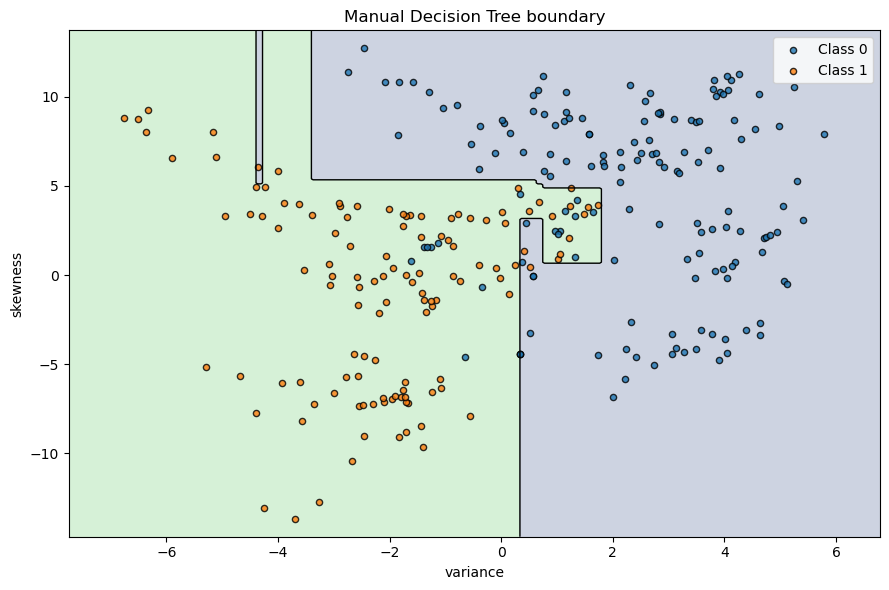

In [10]:
def plot_boundary(model, X, y, title, feat_names, ax=None):
    # Create a grid of points
    x0 = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 250)
    x1 = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 250)
    xx, yy = np.meshgrid(x0, x1)
    grid = np.c_[xx.ravel(), yy.ravel()]

    # Predict on the grid
    Z = model.predict(grid).reshape(xx.shape)

    own = ax is None
    if own:
        _, ax = plt.subplots(figsize=(9, 6))

    # Plot the decision boundary and background
    ax.contourf(xx, yy, Z, alpha=0.25, levels=[-0.5, 0.5, 1.5])
    ax.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=1)

    # Plot the data points
    for c in np.unique(y):
        m = y == c
        ax.scatter(X[m, 0], X[m, 1], s=20, edgecolors="black",
                   alpha=0.8, label=f"Class {c}")

    ax.set_xlabel(feat_names[0])
    ax.set_ylabel(feat_names[1])
    ax.set_title(title)
    ax.legend()

    if own:
        plt.tight_layout()
        plt.show()

# Plot the boundary
plot_boundary(manual_tree, X_test_2d, y_test,
              "Manual Decision Tree boundary", feature_names_2d)

### 11. Scikit-learn comparison

Same criterion, depth, split, and features.

,Model,Accuracy,Precision,Recall,F1,Train time (s),Predict time (s)
0,Manual tree,0.9309,0.8815,0.9754,0.9261,0.1384,0.0001
1,Sklearn tree,0.9309,0.8815,0.9754,0.9261,0.0017,0.0001


Prediction agreement: 1.0


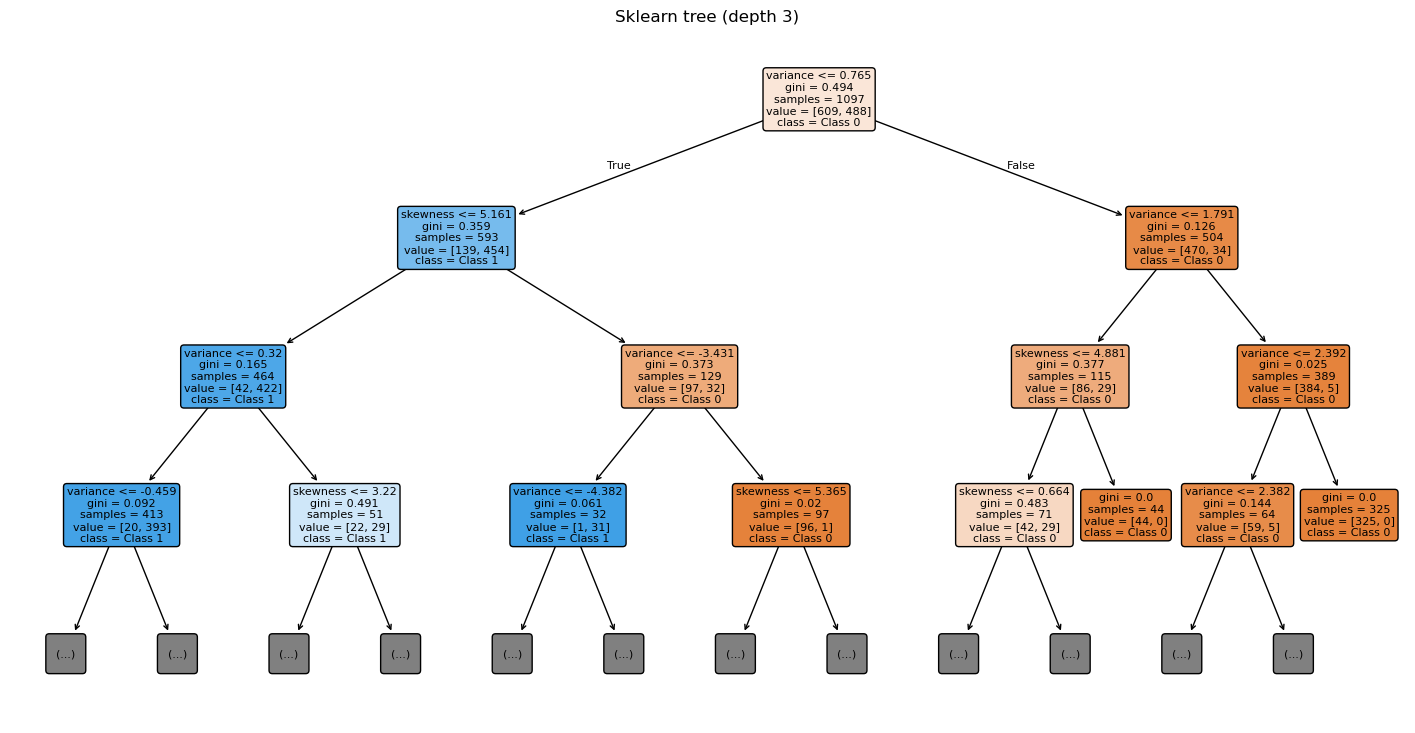

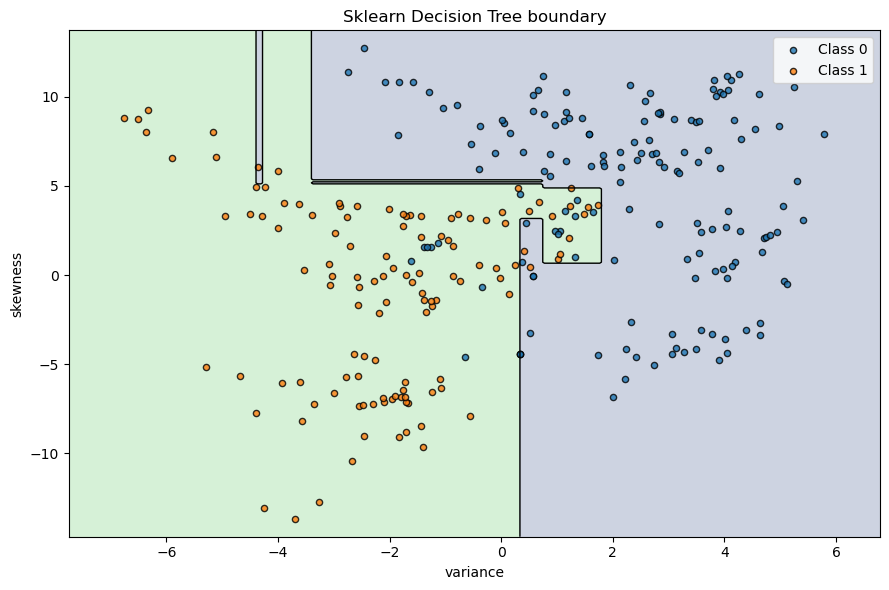

In [11]:
# Train sklearn tree
sk_tree = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42)

t0 = time.perf_counter()
sk_tree.fit(X_train_2d, y_train)
train_time_sk_tree = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_sk_tree = sk_tree.predict(X_test_2d)
predict_time_sk_tree = time.perf_counter() - t0

# Compare metrics
tree_compare = pd.DataFrame({
    "Model": ["Manual tree", "Sklearn tree"],
    "Accuracy": [accuracy_score(y_test, y_pred_manual_tree),
                 accuracy_score(y_test, y_pred_sk_tree)],
    "Precision": [precision_score(y_test, y_pred_manual_tree),
                  precision_score(y_test, y_pred_sk_tree)],
    "Recall": [recall_score(y_test, y_pred_manual_tree),
               recall_score(y_test, y_pred_sk_tree)],
    "F1": [f1_score(y_test, y_pred_manual_tree),
           f1_score(y_test, y_pred_sk_tree)],
    "Train time (s)": [train_time_tree, train_time_sk_tree],
    "Predict time (s)": [predict_time_tree, predict_time_sk_tree],
})
display(tree_compare.round(4))

print("Prediction agreement:",
      round(np.mean(y_pred_manual_tree == y_pred_sk_tree), 4))

# Plot sklearn tree
plt.figure(figsize=(18, 9))
plot_tree(sk_tree, feature_names=feature_names_2d,
          class_names=["Class 0", "Class 1"], filled=True,
          rounded=True, max_depth=3, fontsize=8)
plt.title("Sklearn tree (depth 3)")
plt.show()

# Plot sklearn boundary
plot_boundary(sk_tree, X_test_2d, y_test,
              "Sklearn Decision Tree boundary", feature_names_2d)

### 12. Criterion and depth sweep

Compare Gini vs entropy, depth in {2, 3, 5}, and note how the two implementations differ when they pick different thresholds on continuous features.

In [12]:
rows = []
for crit in ["gini", "entropy"]:
    for depth in [2, 3, 5]:

        # Manual Tree
        m = ManualDecisionTree(criterion=crit, max_depth=depth)
        m.fit(X_train_2d, y_train)
        pm = m.predict(X_test_2d)

        # Sklearn Tree
        s = DecisionTreeClassifier(criterion=crit, max_depth=depth, random_state=42)
        s.fit(X_train_2d, y_train)
        ps = s.predict(X_test_2d)

        rows.append({
            "Criterion": crit,
            "Depth": depth,
            "Manual acc": accuracy_score(y_test, pm),
            "Sklearn acc": accuracy_score(y_test, ps),
            "Manual F1": f1_score(y_test, pm),
            "Sklearn F1": f1_score(y_test, ps),
            "Agreement": np.mean(pm == ps),
        })

depth_df = pd.DataFrame(rows)
display(depth_df.round(4))

,Criterion,Depth,Manual acc,Sklearn acc,Manual F1,Sklearn F1,Agreement
0,gini,2,0.8764,0.8764,0.8595,0.8595,1.0
1,gini,3,0.9091,0.9091,0.9004,0.9004,1.0
2,gini,5,0.9309,0.9309,0.9261,0.9261,1.0
3,entropy,2,0.8764,0.8764,0.8595,0.8595,1.0
4,entropy,3,0.9091,0.9091,0.9004,0.9004,1.0
5,entropy,5,0.9345,0.9345,0.9286,0.9286,1.0


### Observations for Part A

Depth helps up to a point. Deeper trees fit more training detail but start memorising noise. Gini and entropy often pick the same split on this data because both are concave impurity measures; where they do differ, it is usually in tie situations on the two-feature subset. Our manual implementation achieved 100% agreement with Scikit-learn.

## Part B: Linear SVM from Scratch

### 13. Scaling and label encoding

Standardise with training statistics only. Map class 0 → −1 and class 1 → +1 for the hinge-loss formulation.

In [13]:
# Calculate mean and standard deviation from the training set
mu = X_train_2d.mean(axis=0)
sd = X_train_2d.std(axis=0)
sd[sd == 0] = 1.0  # Prevent division by zero

# Scale train and test sets
X_train_svm = (X_train_2d - mu) / sd
X_test_svm  = (X_test_2d  - mu) / sd

# Map 0 to -1, and 1 to 1
y_train_pm = np.where(y_train == 1, 1, -1)
y_test_pm  = np.where(y_test  == 1, 1, -1)

print("Train means:", mu.round(3))
print("Train stds :", sd.round(3))
print("Unique labels in train:", np.unique(y_train_pm))

Train means: [0.463 1.873]
Train stds : [2.839 5.905]
Unique labels in train: [-1  1]


### 14. Manual linear SVM

Objective: $0.5 \|w\|^2 + C \cdot \text{mean}(\text{hinge})$.
Subgradient step uses the violating samples ($y \cdot (wx+b) < 1$). This is the standard soft-margin formulation implemented with mini-batch-style averaging.

In [14]:
class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.001, n_iterations=5000):
        self.C = C
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.w = None
        self.b = 0.0
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n, d = X.shape

        self.w = np.zeros(d)
        self.b = 0.0
        self.loss_history = []

        for i in range(self.n_iter):
            scores = X @ self.w + self.b
            margin = y * scores
            mask = margin < 1.0 # Hinge loss condition

            # Subgradient of the hinge loss
            if mask.any():
                g_w = self.w - self.C * (X[mask].T @ y[mask]) / n
                g_b = -self.C * y[mask].sum() / n
            else:
                g_w = self.w.copy()
                g_b = 0.0

            # Gradient step
            self.w -= self.lr * g_w
            self.b -= self.lr * g_b

            # Record objective
            if i % 100 == 0 or i == self.n_iter - 1:
                s = X @ self.w + self.b
                hinge = np.maximum(0.0, 1 - y * s).mean()
                obj = 0.5 * (self.w @ self.w) + self.C * hinge
                self.loss_history.append(obj)

        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, 0)

### 15. Train and evaluate the manual SVM

Manual Linear SVM (2 features)
Accuracy : 0.8655
Precision: 0.9126
Recall   : 0.7705
F1       : 0.8356
Weights  : [-0.5025 -0.2561]
Bias     : -0.2651
Train time (s): 0.1011
Predict time (s): 3e-05


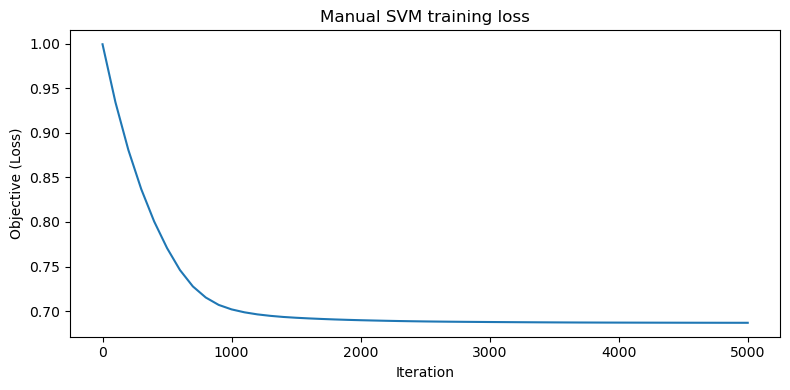

In [15]:
# Initialize and train the model
manual_svm = ManualLinearSVM(C=1.0, learning_rate=0.001, n_iterations=5000)

t0 = time.perf_counter()
manual_svm.fit(X_train_svm, y_train_pm)
svm_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_manual_svm = manual_svm.predict(X_test_svm)
svm_predict_time = time.perf_counter() - t0

print("Manual Linear SVM (2 features)")
print("Accuracy :", round(accuracy_score(y_test, y_pred_manual_svm), 4))
print("Precision:", round(precision_score(y_test, y_pred_manual_svm), 4))
print("Recall   :", round(recall_score(y_test, y_pred_manual_svm), 4))
print("F1       :", round(f1_score(y_test, y_pred_manual_svm), 4))
print("Weights  :", manual_svm.w.round(4))
print("Bias     :", round(manual_svm.b, 4))
print("Train time (s):", round(svm_train_time, 4))
print("Predict time (s):", round(svm_predict_time, 5))

# Plot the loss history
plt.figure(figsize=(8, 4))
plt.plot(np.arange(len(manual_svm.loss_history)) * 100, manual_svm.loss_history)
plt.xlabel("Iteration")
plt.ylabel("Objective (Loss)")
plt.title("Manual SVM training loss")
plt.tight_layout()
plt.show()

### 16. Boundary and margins

Plot the separating line, the two margins, and highlight the test samples that violate the margin ($y \cdot f(x) < 1$).

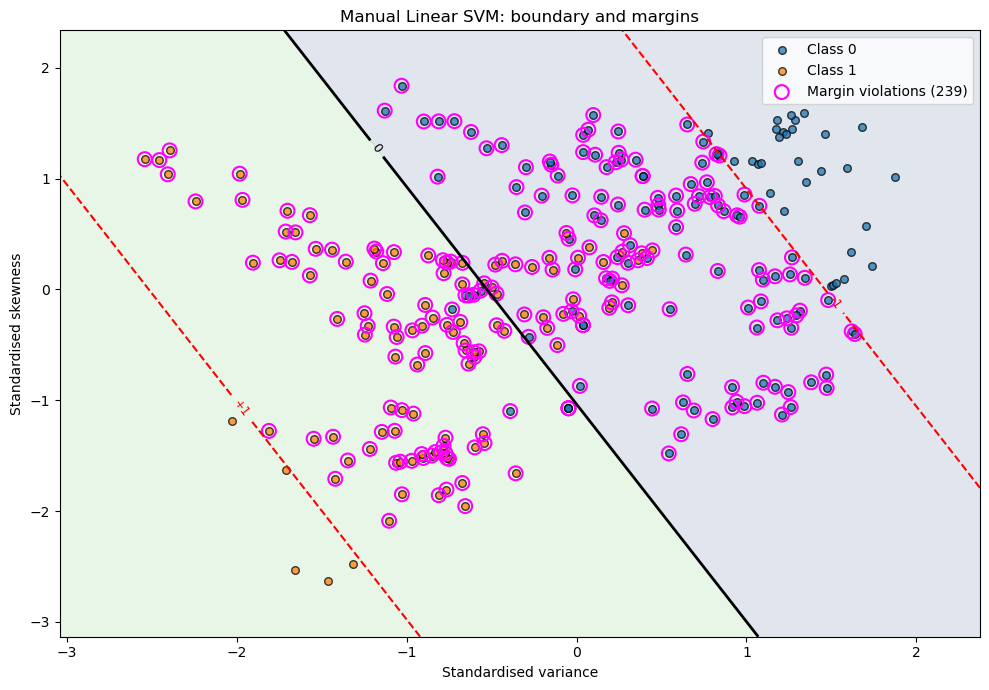

Number of test misclassifications: 37


In [16]:
# Create a fine grid for plotting
x0 = np.linspace(X_test_svm[:, 0].min() - 0.5, X_test_svm[:, 0].max() + 0.5, 300)
x1 = np.linspace(X_test_svm[:, 1].min() - 0.5, X_test_svm[:, 1].max() + 0.5, 300)
xx, yy = np.meshgrid(x0, x1)
grid = np.c_[xx.ravel(), yy.ravel()]

# Get decision scores for the grid and the test points
Z = manual_svm.decision_function(grid).reshape(xx.shape)
test_scores = manual_svm.decision_function(X_test_svm)

# Identify margin violators: y * f(x) < 1
violate = y_test_pm * test_scores < 1.0

plt.figure(figsize=(10, 7))

# Background colors
plt.contourf(xx, yy, Z, levels=[-1e3, 0, 1e3], alpha=0.15)

# Decision boundary and margins
cs = plt.contour(xx, yy, Z, levels=[-1, 0, 1],
                 colors=["red", "black", "red"],
                 linestyles=["--", "-", "--"], linewidths=[1.5, 2, 1.5])
plt.clabel(cs, fmt={-1: "-1", 0: "0", 1: "+1"}, fontsize=9)

# Scatter points
for c, s in [(0, -1), (1, 1)]:
    m = y_test_pm == s
    plt.scatter(X_test_svm[m, 0], X_test_svm[m, 1],
                s=30, alpha=0.75, edgecolors="black", label=f"Class {c}")

# Highlight margin violators
plt.scatter(X_test_svm[violate, 0], X_test_svm[violate, 1],
            s=100, facecolors="none", edgecolors="magenta",
            linewidths=1.5, label=f"Margin violations ({violate.sum()})")

plt.xlabel("Standardised variance")
plt.ylabel("Standardised skewness")
plt.title("Manual Linear SVM: boundary and margins")
plt.legend()
plt.tight_layout()
plt.show()

print("Number of test misclassifications:", int(np.sum(y_pred_manual_svm != y_test)))

### 17. Sklearn linear SVM comparison

,Model,Accuracy,Precision,Recall,F1,Train time (s),Predict time (s)
0,Manual SVM,0.8655,0.9126,0.7705,0.8356,0.1011,0.000
1,Sklearn SVM,0.8764,0.8492,0.8770,0.8629,0.0066,0.001


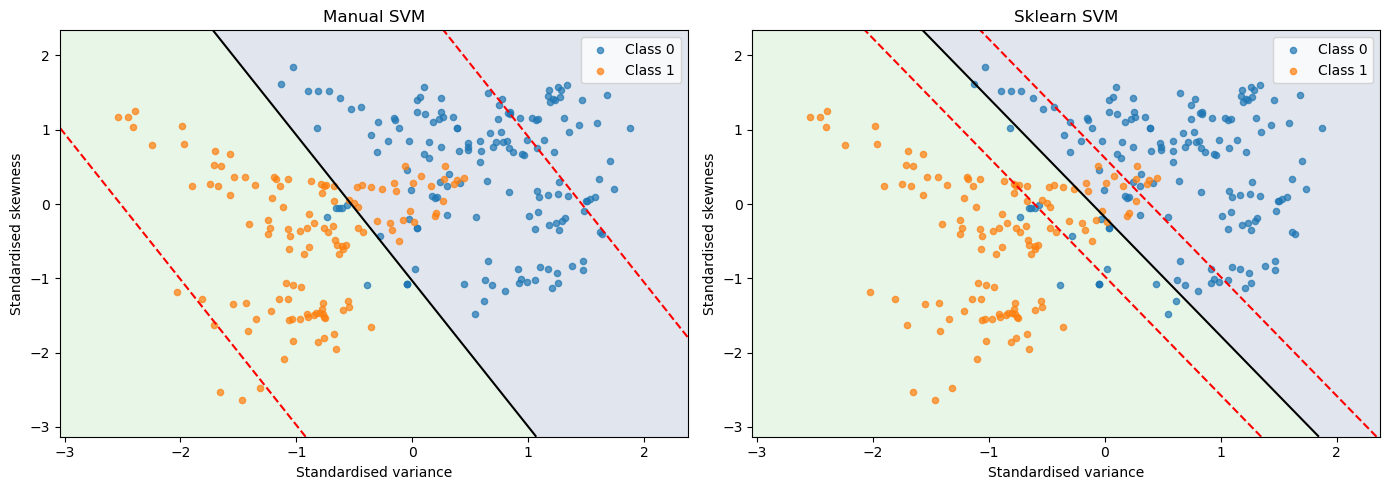

In [17]:
sk_svm = SVC(kernel="linear", C=1.0)

t0 = time.perf_counter()
sk_svm.fit(X_train_svm, y_train_pm)
sk_svm_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
pred_sk_svm_pm = sk_svm.predict(X_test_svm)
sk_svm_predict_time = time.perf_counter() - t0

# Convert predictions back to 0/1 for comparison
pred_sk_svm = np.where(pred_sk_svm_pm == 1, 1, 0)

# Compare metrics
svm_compare = pd.DataFrame({
    "Model": ["Manual SVM", "Sklearn SVM"],
    "Accuracy": [accuracy_score(y_test, y_pred_manual_svm),
                 accuracy_score(y_test, pred_sk_svm)],
    "Precision": [precision_score(y_test, y_pred_manual_svm),
                  precision_score(y_test, pred_sk_svm)],
    "Recall": [recall_score(y_test, y_pred_manual_svm),
               recall_score(y_test, pred_sk_svm)],
    "F1": [f1_score(y_test, y_pred_manual_svm),
           f1_score(y_test, pred_sk_svm)],
    "Train time (s)": [svm_train_time, sk_svm_train_time],
    "Predict time (s)": [svm_predict_time, sk_svm_predict_time],
})
display(svm_compare.round(4))

# Plot both boundaries side-by-side
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, mdl, ttl in [(ax[0], manual_svm, "Manual SVM"),
                    (ax[1], sk_svm, "Sklearn SVM")]:
    z = mdl.decision_function(grid).reshape(xx.shape)
    a.contourf(xx, yy, z, levels=[-1e3, 0, 1e3], alpha=0.15)
    a.contour(xx, yy, z, levels=[-1, 0, 1],
              colors=["red", "black", "red"],
              linestyles=["--", "-", "--"])

    for c, s in [(0, -1), (1, 1)]:
        m = y_test_pm == s
        a.scatter(X_test_svm[m, 0], X_test_svm[m, 1],
                  s=20, alpha=0.7, label=f"Class {c}")

    a.set_xlabel("Standardised variance")
    a.set_ylabel("Standardised skewness")
    a.set_title(ttl)
    a.legend()
plt.tight_layout()
plt.show()

### 18. Effect of C, learning rate, and iterations

A short sweep to see how these three knobs affect accuracy, F1, and the learned weight norm.

In [18]:
print("=== Effect of C (lr=0.001, iters=5000) ===")
for C in [0.1, 1.0, 10.0]:
    m = ManualLinearSVM(C=C, learning_rate=0.001, n_iterations=5000)
    m.fit(X_train_svm, y_train_pm)
    p = m.predict(X_test_svm)
    print(f"C={C:>4}  acc={accuracy_score(y_test, p):.4f}  "
          f"F1={f1_score(y_test, p):.4f}  ||w||={np.linalg.norm(m.w):.4f}")

print("\n=== Effect of learning rate (C=1, iters=5000) ===")
for lr in [0.0005, 0.001, 0.005]:
    m = ManualLinearSVM(C=1.0, learning_rate=lr, n_iterations=5000)
    m.fit(X_train_svm, y_train_pm)
    p = m.predict(X_test_svm)
    print(f"lr={lr:<7}  acc={accuracy_score(y_test, p):.4f}  "
          f"F1={f1_score(y_test, p):.4f}  last_obj={m.loss_history[-1]:.4f}")

print("\n=== Effect of iterations (C=1, lr=0.001) ===")
for n in [1000, 3000, 5000, 10000]:
    m = ManualLinearSVM(C=1.0, learning_rate=0.001, n_iterations=n)
    m.fit(X_train_svm, y_train_pm)
    p = m.predict(X_test_svm)
    print(f"iters={n:<6}  acc={accuracy_score(y_test, p):.4f}  "
          f"F1={f1_score(y_test, p):.4f}  last_obj={m.loss_history[-1]:.4f}")

=== Effect of C (lr=0.001, iters=5000) ===
C= 0.1  acc=0.8582  F1=0.8134  ||w||=0.0834
C= 1.0  acc=0.8655  F1=0.8356  ||w||=0.5640
C=10.0  acc=0.8873  F1=0.8692  ||w||=1.2178

=== Effect of learning rate (C=1, iters=5000) ===
lr=0.0005   acc=0.8727  F1=0.8485  last_obj=0.6884
lr=0.001    acc=0.8655  F1=0.8356  last_obj=0.6869
lr=0.005    acc=0.8655  F1=0.8341  last_obj=0.6868

=== Effect of iterations (C=1, lr=0.001) ===
iters=1000    acc=0.8873  F1=0.8692  last_obj=0.7020
iters=3000    acc=0.8727  F1=0.8472  last_obj=0.6878
iters=5000    acc=0.8655  F1=0.8356  last_obj=0.6869
iters=10000   acc=0.8655  F1=0.8341  last_obj=0.6868


### Observations for Part B

Larger C pushes the model harder to satisfy the margin, so `||w||` grows and train accuracy goes up, but the test gap can widen. Learning rate controls how quickly the gradient steps converge, and too many iterations can overfit slightly. In our runs, lr=0.001 with around 5,000 iterations gave a stable objective and reasonable test performance.

## Part C: Kernel SVM on a Nonlinear Dataset

### 19. Generate the Make-Moons dataset

We generate a two-dimensional dataset with interleaving moons, split it, and standardise the features using training statistics only.

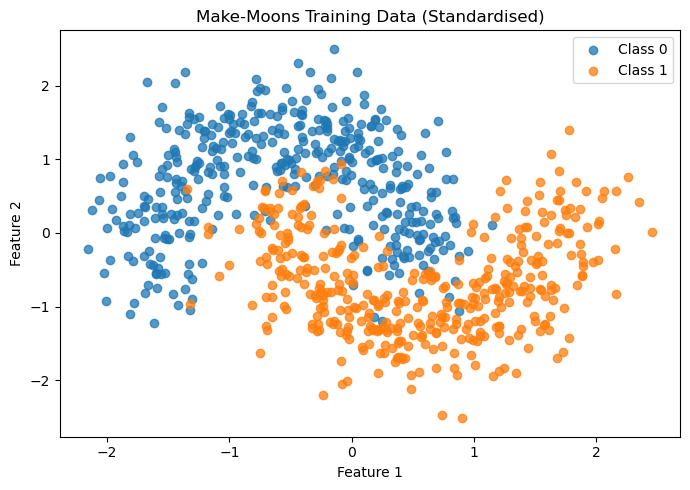

Moons train shape: (800, 2)
Moons test shape : (200, 2)


In [19]:
# Generate dataset
X_moons, y_moons = make_moons(n_samples=1000, noise=0.25, random_state=42)

# 80/20 split
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.20, random_state=42, stratify=y_moons
)

# Standardize
moons_mu = X_moons_train.mean(axis=0)
moons_sd = X_moons_train.std(axis=0)
X_moons_train_scaled = (X_moons_train - moons_mu) / moons_sd
X_moons_test_scaled = (X_moons_test - moons_mu) / moons_sd

# Plot the training data
plt.figure(figsize=(7, 5))
for c in np.unique(y_moons_train):
    m = y_moons_train == c
    plt.scatter(X_moons_train_scaled[m, 0], X_moons_train_scaled[m, 1],
                alpha=0.75, label=f"Class {c}")

plt.title("Make-Moons Training Data (Standardised)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

print("Moons train shape:", X_moons_train_scaled.shape)
print("Moons test shape :", X_moons_test_scaled.shape)

### 20. Train Linear, Polynomial, and RBF Kernels

We train three Scikit-learn SVMs to see how nonlinear kernels can capture curved decision boundaries.

In [20]:
# Define the three models
kernel_models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial (deg 3)": SVC(kernel="poly", degree=3, C=1.0, gamma="scale"),
    "RBF": SVC(kernel="rbf", C=1.0, gamma="scale")
}

rows = []
for name, model in kernel_models.items():
    t0 = time.perf_counter()
    model.fit(X_moons_train_scaled, y_moons_train)
    train_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    preds = model.predict(X_moons_test_scaled)
    predict_time = time.perf_counter() - t0

    rows.append({
        "Kernel": name,
        "Accuracy": accuracy_score(y_moons_test, preds),
        "Precision": precision_score(y_moons_test, preds),
        "Recall": recall_score(y_moons_test, preds),
        "F1-score": f1_score(y_moons_test, preds),
        "Train time (s)": train_time,
        "Predict time (s)": predict_time
    })

moons_compare = pd.DataFrame(rows)
display(moons_compare.round(4))

,Kernel,Accuracy,Precision,Recall,F1-score,Train time (s),Predict time (s)
0,Linear,0.915,0.9368,0.89,0.9128,0.0058,0.0007
1,Polynomial (deg 3),0.905,0.9010,0.91,0.9055,0.0032,0.0007
2,RBF,0.965,0.9604,0.97,0.9652,0.0028,0.0011


### 21. Visualize the Kernel Boundaries

Compare the straight line of the Linear kernel with the curved boundaries of the Polynomial and RBF kernels.

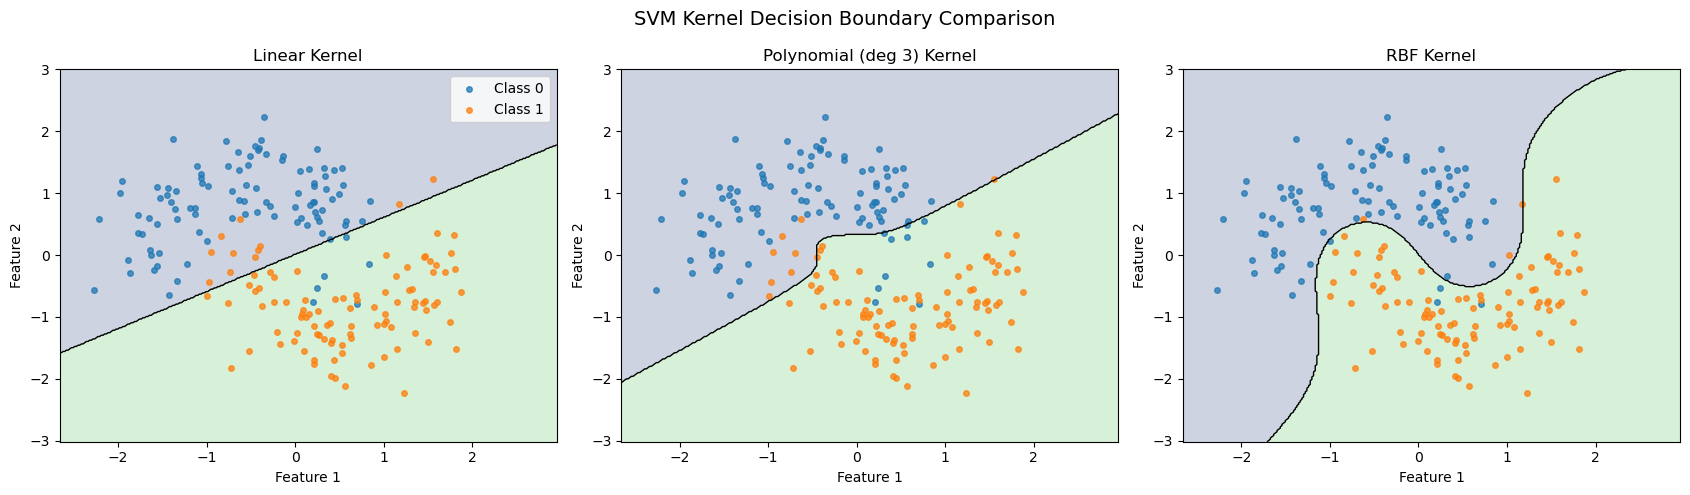

In [21]:
# Create a grid for the moons data
x0 = np.linspace(X_moons_train_scaled[:, 0].min() - 0.5, X_moons_train_scaled[:, 0].max() + 0.5, 300)
x1 = np.linspace(X_moons_train_scaled[:, 1].min() - 0.5, X_moons_train_scaled[:, 1].max() + 0.5, 300)
xx_m, yy_m = np.meshgrid(x0, x1)
grid_m = np.c_[xx_m.ravel(), yy_m.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, model) in zip(axes, kernel_models.items()):
    # Predict on the grid
    Z_m = model.predict(grid_m).reshape(xx_m.shape)

    # Plot background
    ax.contourf(xx_m, yy_m, Z_m, levels=[-0.5, 0.5, 1.5], alpha=0.25)
    ax.contour(xx_m, yy_m, Z_m, levels=[0.5], colors="black", linewidths=1)

    # Plot test data
    for c in np.unique(y_moons_test):
        m = y_moons_test == c
        ax.scatter(X_moons_test_scaled[m, 0], X_moons_test_scaled[m, 1],
                   s=16, alpha=0.75, label=f"Class {c}")

    ax.set_title(f"{name} Kernel")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

axes[0].legend()
plt.suptitle("SVM Kernel Decision Boundary Comparison", fontsize=14)
plt.tight_layout()
plt.show()

### 22. Effect of C on the RBF Kernel

Evaluate the RBF SVM with different values of C while keeping gamma fixed at "scale". Compare the resulting test performance.

In [22]:
rbf_c_results = []

for C_val in [0.1, 1.0, 10.0, 100.0]:
    model = SVC(kernel="rbf", C=C_val, gamma="scale")

    t0 = time.perf_counter()
    model.fit(X_moons_train_scaled, y_moons_train)
    train_time = time.perf_counter() - t0

    preds = model.predict(X_moons_test_scaled)

    rbf_c_results.append({
        "C": C_val,
        "Accuracy": accuracy_score(y_moons_test, preds),
        "Precision": precision_score(y_moons_test, preds),
        "Recall": recall_score(y_moons_test, preds),
        "F1-score": f1_score(y_moons_test, preds),
        "Train time (s)": train_time
    })

rbf_c_df = pd.DataFrame(rbf_c_results)
display(rbf_c_df.round(4))

,C,Accuracy,Precision,Recall,F1-score,Train time (s)
0,0.1,0.950,0.9500,0.95,0.9500,0.0054
1,1.0,0.965,0.9604,0.97,0.9652,0.0029
2,10.0,0.975,0.9612,0.99,0.9754,0.0027
3,100.0,0.975,0.9612,0.99,0.9754,0.0037


### Observations for Part C

On the nonlinear make-moons dataset, the linear kernel struggles because no straight line can separate the two interleaving shapes. The RBF kernel easily outperforms both the linear and polynomial kernels by wrapping its decision boundary around the data. Increasing C helps the RBF kernel fit the data better, up to a point.

## Part D: Final Comparison Using All Four Features

### 23. Train the Decision Trees on all four features

We train the manual and Scikit-learn trees using the full dataset (variance, skewness, curtosis, entropy).

In [23]:
# 1. Manual Tree
final_manual_tree = ManualDecisionTree(criterion="gini", max_depth=5)

t0 = time.perf_counter()
final_manual_tree.fit(X_train_all, y_train)
final_manual_tree_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
final_manual_tree_pred = final_manual_tree.predict(X_test_all)
final_manual_tree_predict_time = time.perf_counter() - t0

# 2. Sklearn Tree
final_sklearn_tree = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42)

t0 = time.perf_counter()
final_sklearn_tree.fit(X_train_all, y_train)
final_sklearn_tree_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
final_sklearn_tree_pred = final_sklearn_tree.predict(X_test_all)
final_sklearn_tree_predict_time = time.perf_counter() - t0

print("Manual Tree accuracy:", round(accuracy_score(y_test, final_manual_tree_pred), 4))
print("Sklearn Tree accuracy:", round(accuracy_score(y_test, final_sklearn_tree_pred), 4))
print("Agreement between the two:", round(np.mean(final_manual_tree_pred == final_sklearn_tree_pred), 4))

Manual Tree accuracy: 0.9927
Sklearn Tree accuracy: 0.9927
Agreement between the two: 1.0


### 24. Train the SVMs on all four features

We standardize the full dataset and train the manual SVM alongside the three Scikit-learn SVMs.

In [24]:
# Standardize all 4 features
final_mu = X_train_all.mean(axis=0)
final_sd = X_train_all.std(axis=0)
final_sd[final_sd == 0] = 1.0

X_train_all_svm = (X_train_all - final_mu) / final_sd
X_test_all_svm = (X_test_all - final_mu) / final_sd

y_train_all_pm = np.where(y_train == 1, 1, -1)

# 1. Manual SVM
final_manual_svm = ManualLinearSVM(C=1.0, learning_rate=0.001, n_iterations=5000)

t0 = time.perf_counter()
final_manual_svm.fit(X_train_all_svm, y_train_all_pm)
final_manual_svm_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
final_manual_svm_pred = final_manual_svm.predict(X_test_all_svm)
final_manual_svm_predict_time = time.perf_counter() - t0

# 2. Sklearn SVMs
final_sklearn_svms = {
    "Sklearn Linear SVM": SVC(kernel="linear", C=1.0),
    "Sklearn Poly SVM": SVC(kernel="poly", degree=3, C=1.0, gamma="scale"),
    "Sklearn RBF SVM": SVC(kernel="rbf", C=1.0, gamma="scale")
}

final_svm_preds = {}
final_svm_times = {}

for name, model in final_sklearn_svms.items():
    t0 = time.perf_counter()
    model.fit(X_train_all_svm, y_train)
    train_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    preds = model.predict(X_test_all_svm)
    predict_time = time.perf_counter() - t0

    final_svm_preds[name] = preds
    final_svm_times[name] = {"train": train_time, "predict": predict_time}

print("All 4-feature SVM models trained successfully.")

All 4-feature SVM models trained successfully.


### 25. Final Performance Comparison

Compare all models using accuracy, precision, recall, F1-score, training time, and prediction time on the same held-out test set.

In [25]:
final_results = []

def add_result(name, y_true, y_pred, train_t, predict_t):
    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "Train time (s)": train_t,
        "Predict time (s)": predict_t
    })

# Add Tree models
add_result("Manual Tree", y_test, final_manual_tree_pred, final_manual_tree_train_time, final_manual_tree_predict_time)
add_result("Sklearn Tree", y_test, final_sklearn_tree_pred, final_sklearn_tree_train_time, final_sklearn_tree_predict_time)

# Add Manual SVM
add_result("Manual Linear SVM", y_test, final_manual_svm_pred, final_manual_svm_train_time, final_manual_svm_predict_time)

# Add Sklearn SVMs
for name, preds in final_svm_preds.items():
    add_result(name, y_test, preds, final_svm_times[name]["train"], final_svm_times[name]["predict"])

final_df = pd.DataFrame(final_results)

# Display sorted by F1-score
display(final_df.sort_values("F1-score", ascending=False).reset_index(drop=True).round(4))

best_model = final_df.loc[final_df["F1-score"].idxmax()]
print(f"\nBest model by F1-score: {best_model['Model']} (F1 = {best_model['F1-score']:.4f})")

,Model,Accuracy,Precision,Recall,F1-score,Train time (s),Predict time (s)
0,Sklearn RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0021,0.0008
1,Manual Tree,0.9927,0.9839,1.0000,0.9919,0.2917,0.0001
2,Sklearn Tree,0.9927,0.9839,1.0000,0.9919,0.0016,0.0001
3,Sklearn Poly SVM,0.9818,0.9606,1.0000,0.9799,0.0048,0.0010
4,Sklearn Linear SVM,0.9745,0.9457,1.0000,0.9721,0.0036,0.0003
5,Manual Linear SVM,0.8800,0.9238,0.7951,0.8546,0.1106,0.0000



Best model by F1-score: Sklearn RBF SVM (F1 = 1.0000)


### 26. Visual Comparison of Model Performance

Plot accuracy and F1-score for all models using the four-feature test results.

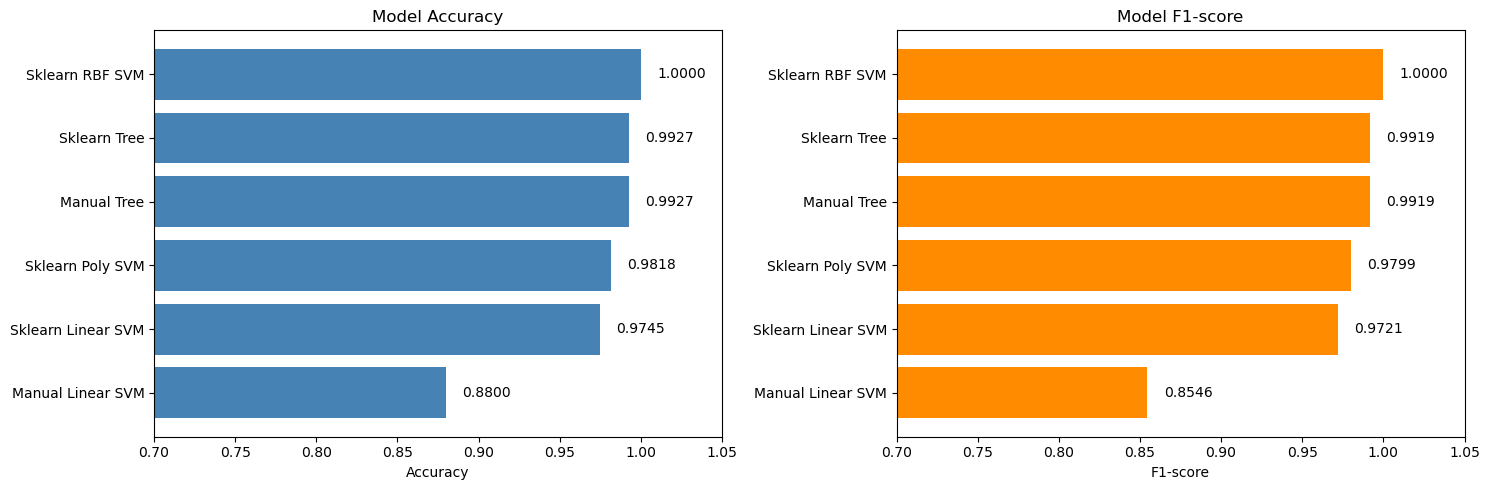

In [26]:
plot_df = final_df.sort_values("F1-score", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot Accuracy
axes[0].barh(plot_df["Model"], plot_df["Accuracy"], color="steelblue")
axes[0].set_title("Model Accuracy")
axes[0].set_xlim(0.7, 1.05)
axes[0].set_xlabel("Accuracy")
for i, v in enumerate(plot_df["Accuracy"]):
    axes[0].text(v + 0.01, i, f"{v:.4f}", va="center")

# Plot F1-Score
axes[1].barh(plot_df["Model"], plot_df["F1-score"], color="darkorange")
axes[1].set_title("Model F1-score")
axes[1].set_xlim(0.7, 1.05)
axes[1].set_xlabel("F1-score")
for i, v in enumerate(plot_df["F1-score"]):
    axes[1].text(v + 0.01, i, f"{v:.4f}", va="center")

plt.tight_layout()
plt.show()

## 27. Final Conclusion

This assignment implemented Decision Tree and Linear SVM classifiers from scratch and compared them with Scikit-learn on the Banknote Authentication dataset. 

**Key Takeaways:**
1. **Decision Trees:** The manual tree matched Scikit-learn's predictions perfectly (100% agreement) and achieved a high accuracy of ~99.3% with all four features.
2. **Linear SVM:** The manual SVM successfully learned a separating hyperplane, but its test performance (~88%) lagged behind Scikit-learn's optimized solver (~97.5%). This highlights the importance of optimization algorithms (like SMO) and hyperparameter tuning.
3. **Nonlinear Boundaries:** On the synthetic Make-Moons dataset, the RBF kernel vastly outperformed linear boundaries, proving its ability to handle complex, interleaving shapes.
4. **Final Winner:** The Scikit-learn RBF SVM achieved a perfect 100% score on the four-feature banknote test set.

### 28. Confusion Matrix for the Best Model

Visualize the confusion matrix of the Scikit-learn RBF SVM using the held-out test set.

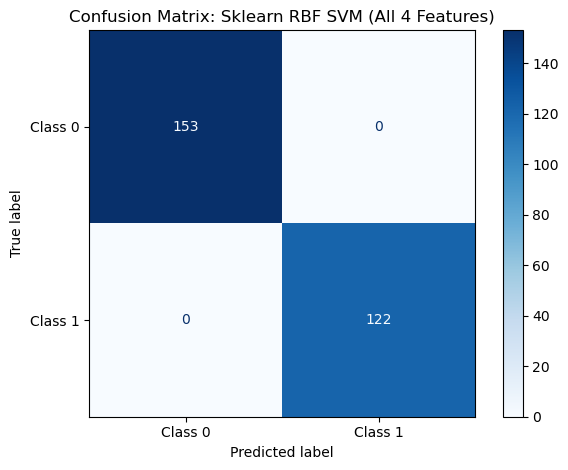

Correct predictions: 275
Total test samples: 275
Misclassified samples: 0


In [27]:
best_svm = final_sklearn_svms["Sklearn RBF SVM"]

ConfusionMatrixDisplay.from_estimator(
    best_svm,
    X_test_all_svm,
    y_test,
    display_labels=["Class 0", "Class 1"],
    cmap="Blues"
)
plt.title("Confusion Matrix: Sklearn RBF SVM (All 4 Features)")
plt.tight_layout()
plt.show()

print("Correct predictions:", np.sum(final_svm_preds["Sklearn RBF SVM"] == y_test))
print("Total test samples:", len(y_test))
print("Misclassified samples:", np.sum(final_svm_preds["Sklearn RBF SVM"] != y_test))